In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, confusion_matrix,
                              roc_auc_score, roc_curve, precision_recall_curve,
                              average_precision_score)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset
import torch.optim as optim

import warnings
warnings.filterwarnings('ignore')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

# Reproducibility
torch.manual_seed(42)
np.random.seed(42)

Device: cpu


In [73]:
import pandas as pd  # add this line
import numpy as np

normal_df = pd.read_csv("ptbdb_normal.csv", header=None)
abnormal_df = pd.read_csv("ptbdb_abnormal.csv", header=None)

print("Normal shape:", normal_df.shape)
print("Abnormal shape:", abnormal_df.shape)

normal_df.head()

Normal shape: (4046, 188)
Abnormal shape: (10506, 188)


,0,1,2,3,4,5,6,7,8,9,...,178,179,180,181,182,183,184,185,186,187
0,1.000000,0.900324,0.358590,0.051459,0.046596,0.126823,0.133306,0.119125,0.110616,0.113047,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.000000,0.794681,0.375387,0.116883,0.000000,0.171923,0.283859,0.293754,0.325912,0.345083,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.909029,0.791482,0.423169,0.186712,0.000000,0.007836,0.063032,0.077002,0.074957,0.077342,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.000000,0.478893,0.056760,0.064176,0.081289,0.072732,0.055619,0.048774,0.054478,0.041643,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.000000,0.867238,0.201360,0.099349,0.141336,0.120934,0.108516,0.096393,0.093436,0.100828,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [74]:
X_normal   = normal_df.iloc[:, :-1].values          # last col = label 0
X_abnormal = abnormal_df.iloc[:, :-1].values         # last col = label 1

# Train ONLY on normal; test on normal + abnormal (unsupervised anomaly detection)
X_train_normal, X_test_normal = train_test_split(
    X_normal, test_size=0.2, random_state=42
)

X_test = np.concatenate([X_test_normal, X_abnormal], axis=0)
y_test = np.concatenate([np.zeros(len(X_test_normal)), np.ones(len(X_abnormal))], axis=0)

print(f"Train Normal : {X_train_normal.shape}")
print(f"Test Set     : {X_test.shape}")
print(f"Test Labels  : {y_test.shape}  (0=normal, 1=abnormal)")

Train Normal : (3236, 187)
Test Set     : (11316, 187)
Test Labels  : (11316,)  (0=normal, 1=abnormal)


In [75]:
scaler = StandardScaler()
X_train_sc = scaler.fit_transform(X_train_normal)
X_test_sc  = scaler.transform(X_test)

print("Train mean ≈", round(X_train_sc.mean(), 6))
print("Train std  ≈", round(X_train_sc.std(),  6))

# ── Tensors & Loaders ─────────────────────────────────────────────────────────
BATCH = 128
input_dim = X_train_sc.shape[1]          # 187

X_train_t = torch.tensor(X_train_sc, dtype=torch.float32)
X_test_t  = torch.tensor(X_test_sc,  dtype=torch.float32)
y_test_t  = torch.tensor(y_test,     dtype=torch.float32)

train_loader = DataLoader(TensorDataset(X_train_t),             batch_size=BATCH, shuffle=True)
test_loader  = DataLoader(TensorDataset(X_test_t, y_test_t),    batch_size=BATCH, shuffle=False)

print("Input dim:", input_dim)

Train mean ≈ -0.0
Train std  ≈ 0.997323
Input dim: 187


In [5]:
class Encoder(nn.Module):
    """Maps input x → (mu, log_var) in latent space."""
    def __init__(self, input_dim, hidden_dims, latent_dim):
        super().__init__()
        layers = []
        prev = input_dim
        for h in hidden_dims:
            layers += [nn.Linear(prev, h), nn.LayerNorm(h), nn.LeakyReLU(0.2)]
            prev = h
        self.shared = nn.Sequential(*layers)
        self.mu      = nn.Linear(prev, latent_dim)
        self.log_var = nn.Linear(prev, latent_dim)

    def forward(self, x):
        h = self.shared(x)
        return self.mu(h), self.log_var(h)


class Decoder(nn.Module):
    """Maps latent vector z → reconstructed signal x̂."""
    def __init__(self, latent_dim, hidden_dims, output_dim):
        super().__init__()
        layers = []
        prev = latent_dim
        for h in reversed(hidden_dims):
            layers += [nn.Linear(prev, h), nn.LayerNorm(h), nn.LeakyReLU(0.2)]
            prev = h
        layers.append(nn.Linear(prev, output_dim))   # no activation → real-valued output
        self.net = nn.Sequential(*layers)

    def forward(self, z):
        return self.net(z)


class VAE(nn.Module):
    def __init__(self, input_dim=187, hidden_dims=[128, 64], latent_dim=16):
        super().__init__()
        self.encoder = Encoder(input_dim, hidden_dims, latent_dim)
        self.decoder = Decoder(latent_dim, hidden_dims, input_dim)

    def reparameterise(self, mu, log_var):
        """z = mu + eps * std  (differentiable sampling)"""
        std = torch.exp(0.5 * log_var)
        eps = torch.randn_like(std)
        return mu + eps * std

    def forward(self, x):
        mu, log_var = self.encoder(x)
        z           = self.reparameterise(mu, log_var)
        x_hat       = self.decoder(z)
        return x_hat, mu, log_var

    def reconstruct(self, x):
        """Deterministic reconstruction (use mean, no sampling)."""
        mu, _ = self.encoder(x)
        return self.decoder(mu)


def vae_loss(x, x_hat, mu, log_var, beta=1.0):
    """ELBO = Reconstruction loss + β·KL divergence"""
    recon = F.mse_loss(x_hat, x, reduction='sum') / x.size(0)
    kl    = -0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp()) / x.size(0)
    return recon + beta * kl, recon, kl


# Instantiate
vae = VAE(input_dim=input_dim, hidden_dims=[128, 64], latent_dim=16).to(device)
print(vae)
print(f"\nTotal params: {sum(p.numel() for p in vae.parameters()):,}")

VAE(
  (encoder): Encoder(
    (shared): Sequential(
      (0): Linear(in_features=187, out_features=128, bias=True)
      (1): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (2): LeakyReLU(negative_slope=0.2)
      (3): Linear(in_features=128, out_features=64, bias=True)
      (4): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (5): LeakyReLU(negative_slope=0.2)
    )
    (mu): Linear(in_features=64, out_features=16, bias=True)
    (log_var): Linear(in_features=64, out_features=16, bias=True)
  )
  (decoder): Decoder(
    (net): Sequential(
      (0): Linear(in_features=16, out_features=64, bias=True)
      (1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
      (2): LeakyReLU(negative_slope=0.2)
      (3): Linear(in_features=64, out_features=128, bias=True)
      (4): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
      (5): LeakyReLU(negative_slope=0.2)
      (6): Linear(in_features=128, out_features=187, bias=True)
    )
  )
)

Total params: 

In [57]:
# ── Cell 6: Train VAE ─────────────────────────────────────────────────────────
VAE_EPOCHS = 50
vae_opt    = optim.Adam(vae.parameters(), lr=1e-3, weight_decay=1e-5)
scheduler  = optim.lr_scheduler.StepLR(vae_opt, step_size=20, gamma=0.5)

vae_history = {'loss': [], 'recon': [], 'kl': []}

vae.train()
for epoch in range(1, VAE_EPOCHS + 1):
    total_loss = total_recon = total_kl = 0.0
    for (xb,) in train_loader:
        xb = xb.to(device)
        x_hat, mu, log_var = vae(xb)
        loss, recon, kl = vae_loss(xb, x_hat, mu, log_var, beta=1.0)

        vae_opt.zero_grad()
        loss.backward()
        nn.utils.clip_grad_norm_(vae.parameters(), 1.0)
        vae_opt.step()

        total_loss  += loss.item()
        total_recon += recon.item()
        total_kl    += kl.item()

    n = len(train_loader)
    vae_history['loss'].append(total_loss / n)
    vae_history['recon'].append(total_recon / n)
    vae_history['kl'].append(total_kl / n)
    scheduler.step()

    if epoch % 10 == 0:
        print(f"Epoch {epoch:3d} | Loss {total_loss/n:.4f} | "
              f"Recon {total_recon/n:.4f} | KL {total_kl/n:.4f}")

print("VAE training complete.")

Epoch  10 | Loss 36.3294 | Recon 20.2732 | KL 16.0563
Epoch  20 | Loss 35.5283 | Recon 19.5783 | KL 15.9501
Epoch  30 | Loss 34.4607 | Recon 18.4929 | KL 15.9678
Epoch  40 | Loss 34.1286 | Recon 18.2646 | KL 15.8640
Epoch  50 | Loss 33.5843 | Recon 17.7274 | KL 15.8569
VAE training complete.


VAE  AUC-ROC : 0.8192
VAE  Avg-Prec: 0.9813

Classification Report:
              precision    recall  f1-score   support

      Normal       0.11      0.95      0.19       810
    Abnormal       0.99      0.39      0.56     10506

    accuracy                           0.43     11316
   macro avg       0.55      0.67      0.37     11316
weighted avg       0.93      0.43      0.53     11316



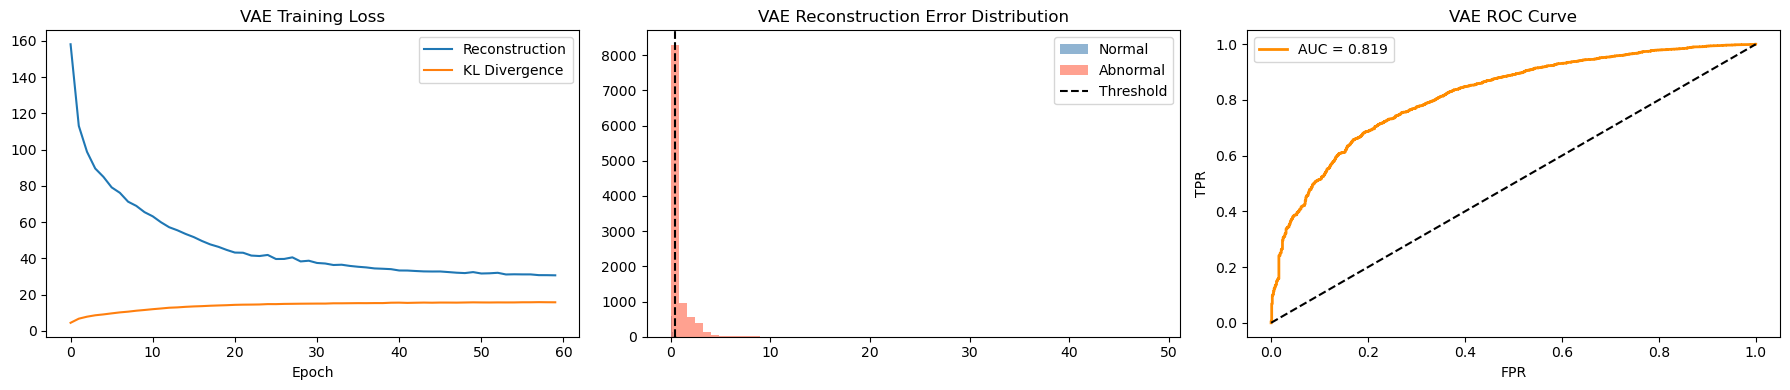

In [7]:
vae.eval()

# Reconstruction errors on test set
vae_scores = []
with torch.no_grad():
    for (xb, _) in test_loader:
        xb   = xb.to(device)
        x_hat = vae.reconstruct(xb)
        err   = ((xb - x_hat) ** 2).mean(dim=1)   # MSE per sample
        vae_scores.extend(err.cpu().numpy())

vae_scores = np.array(vae_scores)

# ── ROC & PR Curves ───────────────────────────────────────────────────────────
vae_auc = roc_auc_score(y_test, vae_scores)
vae_ap  = average_precision_score(y_test, vae_scores)
fpr_v, tpr_v, _ = roc_curve(y_test, vae_scores)

# Best threshold (Youden's J)
best_thresh_v = np.percentile(vae_scores[y_test == 0], 95)  # 95th pct of normal
y_pred_v = (vae_scores > best_thresh_v).astype(int)

print(f"VAE  AUC-ROC : {vae_auc:.4f}")
print(f"VAE  Avg-Prec: {vae_ap:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_v, target_names=['Normal','Abnormal']))

# ── Plots ─────────────────────────────────────────────────────────────────────
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

# Training curve
axes[0].plot(vae_history['recon'], label='Reconstruction')
axes[0].plot(vae_history['kl'],    label='KL Divergence')
axes[0].set_title('VAE Training Loss'); axes[0].legend(); axes[0].set_xlabel('Epoch')

# Score distribution
axes[1].hist(vae_scores[y_test==0], bins=60, alpha=0.6, label='Normal',   color='steelblue')
axes[1].hist(vae_scores[y_test==1], bins=60, alpha=0.6, label='Abnormal', color='tomato')
axes[1].axvline(best_thresh_v, color='k', linestyle='--', label='Threshold')
axes[1].set_title('VAE Reconstruction Error Distribution'); axes[1].legend()

# ROC
axes[2].plot(fpr_v, tpr_v, color='darkorange', lw=2, label=f'AUC = {vae_auc:.3f}')
axes[2].plot([0,1],[0,1],'k--'); axes[2].set_title('VAE ROC Curve')
axes[2].set_xlabel('FPR'); axes[2].set_ylabel('TPR'); axes[2].legend()

plt.tight_layout()
plt.savefig('vae_results.png', dpi=150)
plt.show()

In [8]:
class Generator(nn.Module):
    """Maps noise z → fake normal ECG signal."""
    def __init__(self, noise_dim=64, hidden_dims=[64, 128, 256], output_dim=187):
        super().__init__()
        layers = []
        prev = noise_dim
        for h in hidden_dims:
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU(True)]
            prev = h
        layers.append(nn.Linear(prev, output_dim))   # output in R^187 (standardised)
        self.net = nn.Sequential(*layers)

    def forward(self, z):
        return self.net(z)


class Critic(nn.Module):
    """WGAN critic: outputs scalar score (NOT probability — no sigmoid).
       High score → looks like real normal data."""
    def __init__(self, input_dim=187, hidden_dims=[256, 128, 64]):
        super().__init__()
        layers = []
        prev = input_dim
        for h in hidden_dims:
            # LayerNorm instead of BatchNorm in Critic (WGAN best practice)
            layers += [nn.Linear(prev, h), nn.LayerNorm(h), nn.LeakyReLU(0.2, True)]
            prev = h
        layers.append(nn.Linear(prev, 1))             # scalar score
        self.net = nn.Sequential(*layers)

    def forward(self, x):
        return self.net(x)


NOISE_DIM = 64
gen  = Generator(noise_dim=NOISE_DIM, hidden_dims=[64, 128, 256], output_dim=input_dim).to(device)
crit = Critic(input_dim=input_dim,    hidden_dims=[256, 128, 64]).to(device)

print("Generator:\n", gen)
print("\nCritic:\n", crit)

Generator:
 Generator(
  (net): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): BatchNorm1d(64, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Linear(in_features=64, out_features=128, bias=True)
    (4): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): Linear(in_features=128, out_features=256, bias=True)
    (7): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (8): ReLU(inplace=True)
    (9): Linear(in_features=256, out_features=187, bias=True)
  )
)

Critic:
 Critic(
  (net): Sequential(
    (0): Linear(in_features=187, out_features=256, bias=True)
    (1): LayerNorm((256,), eps=1e-05, elementwise_affine=True)
    (2): LeakyReLU(negative_slope=0.2, inplace=True)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): LayerNorm((128,), eps=1e-05, elementwise_affine=True)
    (5): L

In [9]:
WGAN_EPOCHS  = 100
N_CRITIC     = 5          # critic steps per generator step
CLIP_VALUE   = 0.01       # weight clipping for Lipschitz constraint
LR_GEN       = 5e-5
LR_CRIT      = 5e-5

opt_gen  = optim.RMSprop(gen.parameters(),  lr=LR_GEN)
opt_crit = optim.RMSprop(crit.parameters(), lr=LR_CRIT)

wgan_history = {'critic_loss': [], 'gen_loss': []}

for epoch in range(1, WGAN_EPOCHS + 1):
    gen.train(); crit.train()
    epoch_c_loss = epoch_g_loss = 0.0
    n_batches = 0

    for (real,) in train_loader:
        real = real.to(device)
        bs   = real.size(0)

        # ─── Train Critic N_CRITIC times ───────────────────────────────────
        for _ in range(N_CRITIC):
            z    = torch.randn(bs, NOISE_DIM, device=device)
            fake = gen(z).detach()

            # Wasserstein loss: max E[C(real)] - E[C(fake)]
            loss_c = -(crit(real).mean() - crit(fake).mean())

            opt_crit.zero_grad()
            loss_c.backward()
            opt_crit.step()

            # Weight clipping (Lipschitz constraint)
            for p in crit.parameters():
                p.data.clamp_(-CLIP_VALUE, CLIP_VALUE)

        # ─── Train Generator ───────────────────────────────────────────────
        z    = torch.randn(bs, NOISE_DIM, device=device)
        fake = gen(z)
        loss_g = -crit(fake).mean()     # max E[C(fake)]  ↔  min -E[C(fake)]

        opt_gen.zero_grad()
        loss_g.backward()
        opt_gen.step()

        epoch_c_loss += loss_c.item()
        epoch_g_loss += loss_g.item()
        n_batches    += 1

    wgan_history['critic_loss'].append(epoch_c_loss / n_batches)
    wgan_history['gen_loss'].append(epoch_g_loss / n_batches)

    if epoch % 20 == 0:
        print(f"Epoch {epoch:3d} | Critic Loss {epoch_c_loss/n_batches:.4f} | "
              f"Gen Loss {epoch_g_loss/n_batches:.4f}")

print("WGAN training complete.")

Epoch  20 | Critic Loss -0.0122 | Gen Loss -0.0027
Epoch  40 | Critic Loss -0.0123 | Gen Loss -0.0027
Epoch  60 | Critic Loss -0.0122 | Gen Loss -0.0028
Epoch  80 | Critic Loss -0.0118 | Gen Loss -0.0029
Epoch 100 | Critic Loss -0.0114 | Gen Loss -0.0031
WGAN training complete.


WGAN AUC-ROC : 0.4733
WGAN Avg-Prec: 0.9284

Classification Report:
              precision    recall  f1-score   support

      Normal       0.07      0.95      0.13       810
    Abnormal       0.94      0.06      0.12     10506

    accuracy                           0.13     11316
   macro avg       0.51      0.51      0.13     11316
weighted avg       0.88      0.13      0.12     11316



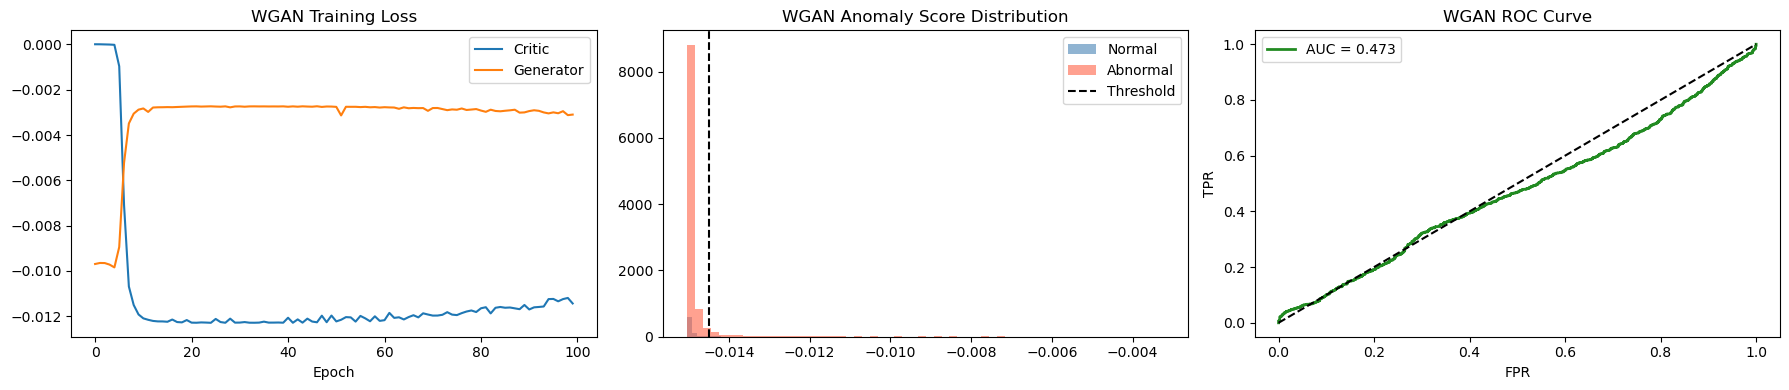

In [10]:
crit.eval()

wgan_scores = []
with torch.no_grad():
    for (xb, _) in test_loader:
        xb = xb.to(device)
        s  = -crit(xb).squeeze()       # negate so high = anomalous
        wgan_scores.extend(s.cpu().numpy())

wgan_scores = np.array(wgan_scores)

wgan_auc = roc_auc_score(y_test, wgan_scores)
wgan_ap  = average_precision_score(y_test, wgan_scores)
fpr_w, tpr_w, _ = roc_curve(y_test, wgan_scores)

best_thresh_w = np.percentile(wgan_scores[y_test == 0], 95)
y_pred_w = (wgan_scores > best_thresh_w).astype(int)

print(f"WGAN AUC-ROC : {wgan_auc:.4f}")
print(f"WGAN Avg-Prec: {wgan_ap:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_w, target_names=['Normal','Abnormal']))

# Plots
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

axes[0].plot(wgan_history['critic_loss'], label='Critic'); axes[0].plot(wgan_history['gen_loss'], label='Generator')
axes[0].set_title('WGAN Training Loss'); axes[0].legend(); axes[0].set_xlabel('Epoch')

axes[1].hist(wgan_scores[y_test==0], bins=60, alpha=0.6, label='Normal',   color='steelblue')
axes[1].hist(wgan_scores[y_test==1], bins=60, alpha=0.6, label='Abnormal', color='tomato')
axes[1].axvline(best_thresh_w, color='k', linestyle='--', label='Threshold')
axes[1].set_title('WGAN Anomaly Score Distribution'); axes[1].legend()

axes[2].plot(fpr_w, tpr_w, color='forestgreen', lw=2, label=f'AUC = {wgan_auc:.3f}')
axes[2].plot([0,1],[0,1],'k--'); axes[2].set_title('WGAN ROC Curve')
axes[2].set_xlabel('FPR'); axes[2].set_ylabel('TPR'); axes[2].legend()

plt.tight_layout()
plt.savefig('wgan_results.png', dpi=150)
plt.show()

In [11]:
def augment_ecg(x: torch.Tensor) -> torch.Tensor:
    """
    Random composition of four ECG-specific augmentations:
      1. Gaussian noise        — simulates measurement noise
      2. Amplitude scaling     — simulates lead gain variation
      3. Time shifting         — circular roll along the time axis
      4. Random channel masking — zeroes out random segments
    """
    aug = x.clone()

    # 1. Gaussian noise
    if torch.rand(1) > 0.3:
        aug = aug + 0.05 * torch.randn_like(aug)

    # 2. Amplitude scaling
    if torch.rand(1) > 0.3:
        scale = 0.8 + 0.4 * torch.rand(1)         # scale ∈ [0.8, 1.2]
        aug = aug * scale.to(x.device)

    # 3. Time shift (circular roll)
    if torch.rand(1) > 0.3:
        shift = int(torch.randint(1, 20, (1,)).item())
        aug = torch.roll(aug, shifts=shift, dims=-1)

    # 4. Random masking of a contiguous segment
    if torch.rand(1) > 0.5:
        L     = aug.shape[-1]
        start = int(torch.randint(0, L - 20, (1,)).item())
        width = int(torch.randint(10, 30, (1,)).item())
        aug[..., start:start + width] = 0.0

    return aug


class ContrastiveDataset(Dataset):
    """Returns two independently augmented views of each sample."""
    def __init__(self, X: np.ndarray):
        self.X = torch.tensor(X, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        x  = self.X[idx]
        x1 = augment_ecg(x)
        x2 = augment_ecg(x)
        return x1, x2


contrast_loader = DataLoader(
    ContrastiveDataset(X_train_sc),
    batch_size=256, shuffle=True, drop_last=True
)
print("Contrastive loader ready.")

Contrastive loader ready.


In [14]:
# ── Cell 12: SimCLR Encoder + Projection Head ─────────────────────────────────
class ContrastiveEncoder(nn.Module):
    """
    Backbone encoder: input → 128-dim normalised embedding.
    Followed by a 2-layer MLP projection head used only during training.
    """
    def __init__(self, input_dim=187, hidden_dims=[256, 128], embed_dim=64, proj_dim=32):
        super().__init__()

        # ─── Backbone ─────────────────────────────────────────────────────────
        backbone = []
        prev = input_dim
        for h in hidden_dims:
            backbone += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU(True)]
            prev = h
        backbone.append(nn.Linear(prev, embed_dim))
        self.backbone = nn.Sequential(*backbone)

        # ─── Projection head (only used for NT-Xent loss) ─────────────────────
        self.projector = nn.Sequential(
            nn.Linear(embed_dim, embed_dim),
            nn.ReLU(True),
            nn.Linear(embed_dim, proj_dim)
        )

    def encode(self, x):
        """Returns L2-normalised backbone embedding (used at inference)."""
        h = self.backbone(x)
        return F.normalize(h, dim=1)

    def forward(self, x):
        """Returns L2-normalised projection (used during training)."""
        z = self.projector(self.backbone(x))
        return F.normalize(z, dim=1)


def nt_xent_loss(z1, z2, temperature=0.5):
    """
    Normalised Temperature-scaled Cross Entropy (NT-Xent) loss.
    Pulls together positive pairs (z1_i, z2_i) and pushes apart negatives.
    """
    N  = z1.size(0)
    z  = torch.cat([z1, z2], dim=0)              # (2N, d)
    sim = torch.mm(z, z.T) / temperature          # cosine sim matrix (2N, 2N)

    # Mask self-similarity
    mask = torch.eye(2 * N, dtype=torch.bool, device=z.device)
    sim.masked_fill_(mask, float('-inf'))

    # Positive pairs: (i, i+N) and (i+N, i)
    pos = torch.cat([torch.arange(N, 2*N), torch.arange(0, N)]).to(z.device)
    loss = F.cross_entropy(sim, pos)
    return loss


EMBED_DIM = 64
enc = ContrastiveEncoder(input_dim=input_dim, hidden_dims=[256, 128],
                          embed_dim=EMBED_DIM, proj_dim=32).to(device)
print(enc)
print(f"\nTotal params: {sum(p.numel() for p in enc.parameters()):,}")

ContrastiveEncoder(
  (backbone): Sequential(
    (0): Linear(in_features=187, out_features=256, bias=True)
    (1): BatchNorm1d(256, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (2): ReLU(inplace=True)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): BatchNorm1d(128, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
    (5): ReLU(inplace=True)
    (6): Linear(in_features=128, out_features=64, bias=True)
  )
  (projector): Sequential(
    (0): Linear(in_features=64, out_features=64, bias=True)
    (1): ReLU(inplace=True)
    (2): Linear(in_features=64, out_features=32, bias=True)
  )
)

Total params: 96,288


In [15]:
# ── Cell 13: Train Contrastive Model ──────────────────────────────────────────
CL_EPOCHS = 80
TEMPERATURE = 0.5

cl_opt       = optim.Adam(enc.parameters(), lr=3e-4, weight_decay=1e-4)
cl_scheduler = optim.lr_scheduler.CosineAnnealingLR(cl_opt, T_max=CL_EPOCHS)

cl_history = []

enc.train()
for epoch in range(1, CL_EPOCHS + 1):
    total_loss = 0.0
    for x1, x2 in contrast_loader:
        x1, x2 = x1.to(device), x2.to(device)
        z1, z2  = enc(x1), enc(x2)
        loss    = nt_xent_loss(z1, z2, temperature=TEMPERATURE)

        cl_opt.zero_grad()
        loss.backward()
        cl_opt.step()
        total_loss += loss.item()

    avg = total_loss / len(contrast_loader)
    cl_history.append(avg)
    cl_scheduler.step()

    if epoch % 10 == 0:
        print(f"Epoch {epoch:3d} | NT-Xent Loss: {avg:.4f}")

print("Contrastive training complete.")

Epoch  10 | NT-Xent Loss: 4.7393
Epoch  20 | NT-Xent Loss: 4.6600
Epoch  30 | NT-Xent Loss: 4.6252
Epoch  40 | NT-Xent Loss: 4.6073
Epoch  50 | NT-Xent Loss: 4.5858
Epoch  60 | NT-Xent Loss: 4.5846
Epoch  70 | NT-Xent Loss: 4.5805
Epoch  80 | NT-Xent Loss: 4.5798
Contrastive training complete.


CL   AUC-ROC : 0.3907
CL   Avg-Prec: 0.8965

Classification Report:
              precision    recall  f1-score   support

      Normal       0.07      0.95      0.13       810
    Abnormal       0.82      0.02      0.03     10506

    accuracy                           0.08     11316
   macro avg       0.44      0.48      0.08     11316
weighted avg       0.76      0.08      0.04     11316



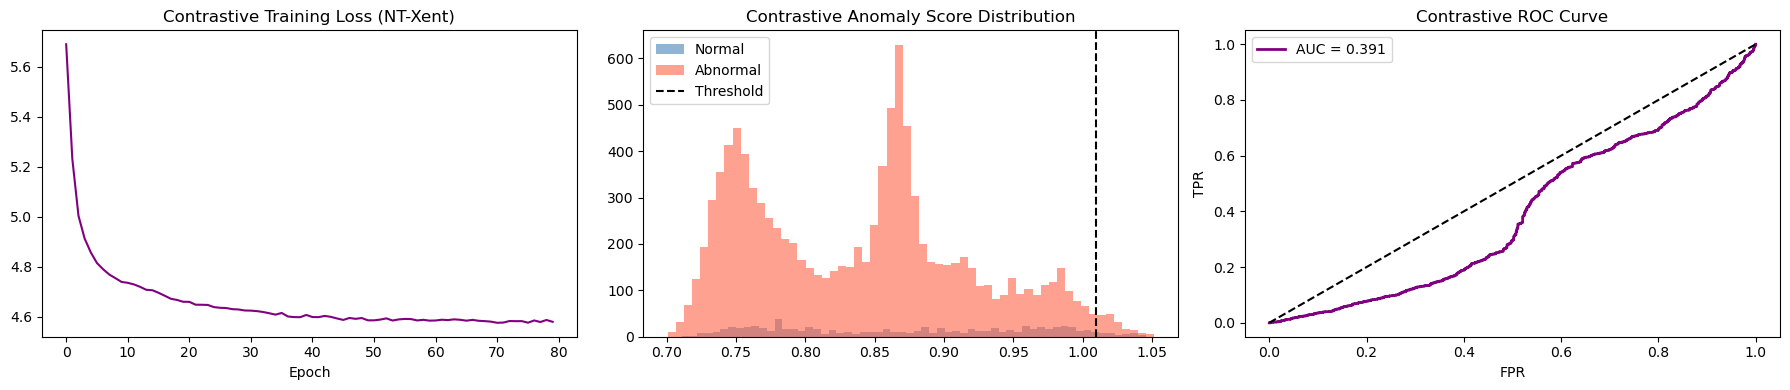

In [18]:
# ── Cell 14: Contrastive Evaluation ──────────────────────────────────────────
# Anomaly score = distance from the centroid of normal embeddings
enc.eval()

# 1. Build normal centroid from training data
train_embeds = []
with torch.no_grad():
    for (xb,) in train_loader:
        e = enc.encode(xb.to(device))
        train_embeds.append(e.cpu())
train_embeds = torch.cat(train_embeds, dim=0)
normal_centroid = train_embeds.mean(dim=0)        # (embed_dim,)

# 2. Score test samples
cl_scores = []
with torch.no_grad():
    for (xb, _) in test_loader:
        e    = enc.encode(xb.to(device)).cpu()
        dist = ((e - normal_centroid) ** 2).sum(dim=1).sqrt()   # L2 distance
        cl_scores.extend(dist.numpy())

cl_scores = np.array(cl_scores)

cl_auc = roc_auc_score(y_test, cl_scores)
cl_ap  = average_precision_score(y_test, cl_scores)
fpr_c, tpr_c, _ = roc_curve(y_test, cl_scores)

best_thresh_c = np.percentile(cl_scores[y_test == 0], 95)
y_pred_c = (cl_scores > best_thresh_c).astype(int)

print(f"CL   AUC-ROC : {cl_auc:.4f}")
print(f"CL   Avg-Prec: {cl_ap:.4f}")
print("\nClassification Report:")
print(classification_report(y_test, y_pred_c, target_names=['Normal','Abnormal']))

# Plots
fig, axes = plt.subplots(1, 3, figsize=(18, 4))

axes[0].plot(cl_history, color='purple')
axes[0].set_title('Contrastive Training Loss (NT-Xent)'); axes[0].set_xlabel('Epoch')

axes[1].hist(cl_scores[y_test==0], bins=60, alpha=0.6, label='Normal',   color='steelblue')
axes[1].hist(cl_scores[y_test==1], bins=60, alpha=0.6, label='Abnormal', color='tomato')
axes[1].axvline(best_thresh_c, color='k', linestyle='--', label='Threshold')
axes[1].set_title('Contrastive Anomaly Score Distribution'); axes[1].legend()

axes[2].plot(fpr_c, tpr_c, color='purple', lw=2, label=f'AUC = {cl_auc:.3f}')
axes[2].plot([0,1],[0,1],'k--'); axes[2].set_title('Contrastive ROC Curve')
axes[2].set_xlabel('FPR'); axes[2].set_ylabel('TPR'); axes[2].legend()

plt.tight_layout()
plt.savefig('cl_results.png', dpi=150)
plt.show()

In [19]:
# ── Cell 15: Score Normalisation ──────────────────────────────────────────────
def normalize(arr):
    return (arr - arr.min()) / (arr.max() - arr.min() + 1e-8)

vae_s  = normalize(vae_scores)
wgan_s = normalize(wgan_scores)
cl_s   = normalize(cl_scores)

print("Score ranges:")
print("VAE :", vae_s.min(), vae_s.max())
print("WGAN:", wgan_s.min(), wgan_s.max())
print("CL  :", cl_s.min(), cl_s.max())

Score ranges:
VAE : 0.0 1.0
WGAN: 0.0 0.9999991
CL  : 0.0 1.0


In [20]:
# ── Cell 16: Individual Model Predictions ─────────────────────────────────────
y_pred_vae  = (vae_scores  > best_thresh_v).astype(int)
y_pred_wgan = (wgan_scores > best_thresh_w).astype(int)
y_pred_cl   = (cl_scores   > best_thresh_c).astype(int)

# Stack predictions
pred_matrix = np.vstack([y_pred_vae, y_pred_wgan, y_pred_cl]).T  # (N, 3)

print("Sample prediction matrix (first 10):")
print(pred_matrix[:10])

Sample prediction matrix (first 10):
[[0 0 0]
 [0 0 0]
 [0 0 0]
 [0 0 0]
 [0 0 0]
 [1 0 0]
 [1 0 0]
 [0 0 0]
 [0 0 0]
 [0 0 0]]


In [21]:
# ── Cell 17: Hybrid Fusion ────────────────────────────────────────────────────

# Weighted hybrid score (tunable)
w_vae, w_wgan, w_cl = 0.4, 0.3, 0.3

hybrid_score = (w_vae * vae_s +
                w_wgan * wgan_s +
                w_cl * cl_s)

# Voting (at least 2 models must agree)
votes = pred_matrix.sum(axis=1)
hybrid_pred = (votes >= 2).astype(int)

print("Hybrid anomaly count:", hybrid_pred.sum())

Hybrid anomaly count: 373


In [22]:
# ── Cell 18: Secondary Filtering (Outliers among Outliers) ────────────────────

# Consider only candidates flagged by hybrid
candidate_idx = np.where(hybrid_pred == 1)[0]
candidate_scores = hybrid_score[candidate_idx]

# Second-level threshold (top anomalies)
refined_threshold = np.percentile(candidate_scores, 75)

refined_pred = np.zeros_like(hybrid_pred)
refined_pred[candidate_idx] = (candidate_scores > refined_threshold).astype(int)

print("Refined anomalies:", refined_pred.sum())

Refined anomalies: 93


In [23]:
# ── Cell 19: Ranking ─────────────────────────────────────────────────────────

# Rank ALL samples
rank_indices = np.argsort(-hybrid_score)

print("\n🔝 Top 20 Most Anomalous Samples:")
for i in rank_indices[:20]:
    print(f"Index: {i}, Score: {hybrid_score[i]:.4f}, True Label: {int(y_test[i])}")

# Rank only refined anomalies
refined_idx = np.where(refined_pred == 1)[0]
refined_rank = refined_idx[np.argsort(-hybrid_score[refined_idx])]

print("\n🔥 Top Refined Anomalies:")
for i in refined_rank[:20]:
    print(f"Index: {i}, Score: {hybrid_score[i]:.4f}, True Label: {int(y_test[i])}")


🔝 Top 20 Most Anomalous Samples:
Index: 7503, Score: 0.6366, True Label: 1
Index: 9418, Score: 0.5778, True Label: 1
Index: 5168, Score: 0.5024, True Label: 1
Index: 7864, Score: 0.4880, True Label: 1
Index: 6694, Score: 0.4827, True Label: 1
Index: 7130, Score: 0.4712, True Label: 1
Index: 5877, Score: 0.4665, True Label: 1
Index: 9760, Score: 0.4553, True Label: 1
Index: 2403, Score: 0.4345, True Label: 1
Index: 10306, Score: 0.4268, True Label: 1
Index: 5869, Score: 0.4101, True Label: 1
Index: 5466, Score: 0.3887, True Label: 1
Index: 7371, Score: 0.3843, True Label: 1
Index: 2779, Score: 0.3710, True Label: 1
Index: 1318, Score: 0.3673, True Label: 1
Index: 10487, Score: 0.3667, True Label: 1
Index: 2328, Score: 0.3641, True Label: 1
Index: 1758, Score: 0.3620, True Label: 1
Index: 8600, Score: 0.3620, True Label: 1
Index: 9419, Score: 0.3596, True Label: 1

🔥 Top Refined Anomalies:
Index: 9834, Score: 0.3312, True Label: 1
Index: 10917, Score: 0.3173, True Label: 1
Index: 4139, 


HYBRID AUC-ROC : 0.4129
HYBRID AvgPrec : 0.9076

Hybrid Classification Report:
              precision    recall  f1-score   support

      Normal       0.07      1.00      0.13       810
    Abnormal       1.00      0.01      0.02     10506

    accuracy                           0.08     11316
   macro avg       0.54      0.50      0.08     11316
weighted avg       0.93      0.08      0.03     11316



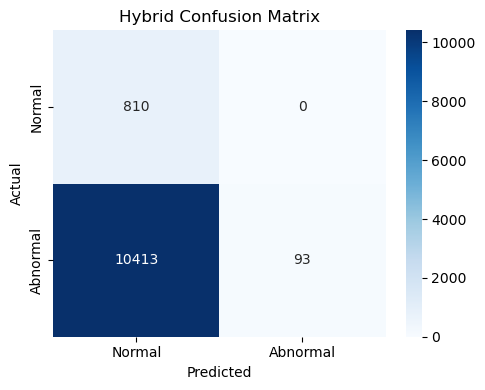

In [24]:
# ── Cell 20: Hybrid Evaluation ───────────────────────────────────────────────

hybrid_auc = roc_auc_score(y_test, hybrid_score)
hybrid_ap  = average_precision_score(y_test, hybrid_score)

print(f"\nHYBRID AUC-ROC : {hybrid_auc:.4f}")
print(f"HYBRID AvgPrec : {hybrid_ap:.4f}")

print("\nHybrid Classification Report:")
print(classification_report(y_test, refined_pred, target_names=['Normal','Abnormal']))

cm = confusion_matrix(y_test, refined_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal','Abnormal'],
            yticklabels=['Normal','Abnormal'])
plt.title("Hybrid Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig("hybrid_cm.png", dpi=150)
plt.show()

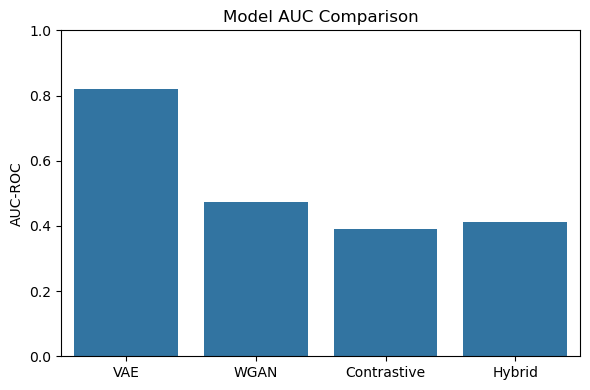

In [25]:
# ── Cell 21: Model Comparison ────────────────────────────────────────────────

models = ['VAE', 'WGAN', 'Contrastive', 'Hybrid']
auc_scores = [vae_auc, wgan_auc, cl_auc, hybrid_auc]

plt.figure(figsize=(6,4))
sns.barplot(x=models, y=auc_scores)
plt.title("Model AUC Comparison")
plt.ylabel("AUC-ROC")
plt.ylim(0,1)
plt.tight_layout()
plt.savefig("model_comparison.png", dpi=150)
plt.show()


HYBRID AUC-ROC : 0.4012
HYBRID AvgPrec : 0.9011

Best Threshold: 0.0033
Best F1 Score: 0.9629

Hybrid Classification Report:
              precision    recall  f1-score   support

      Normal       0.00      0.00      0.00       810
    Abnormal       0.93      1.00      0.96     10506

    accuracy                           0.93     11316
   macro avg       0.46      0.50      0.48     11316
weighted avg       0.86      0.93      0.89     11316



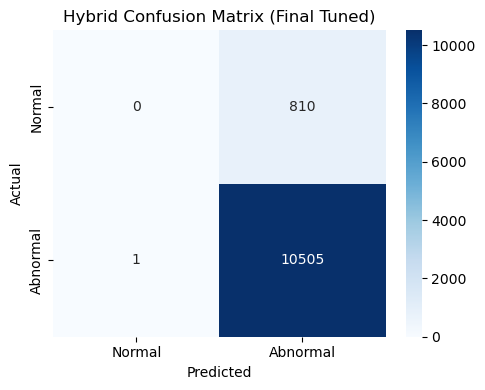

In [53]:
from sklearn.metrics import (classification_report, roc_auc_score, 
                             average_precision_score, precision_recall_curve,
                             confusion_matrix, f1_score)
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# 🔹 1. AUC & Average Precision
hybrid_auc = roc_auc_score(y_test, hybrid_score)
hybrid_ap  = average_precision_score(y_test, hybrid_score)

print(f"\nHYBRID AUC-ROC : {hybrid_auc:.4f}")
print(f"HYBRID AvgPrec : {hybrid_ap:.4f}")

# 🔹 2. BEST THRESHOLD (F1 OPTIMIZATION ⭐)
prec, rec, thresh = precision_recall_curve(y_test, hybrid_score)

f1_scores = 2 * (prec * rec) / (prec + rec + 1e-8)
best_idx = np.argmax(f1_scores)
best_thresh = thresh[best_idx]

print(f"\nBest Threshold: {best_thresh:.4f}")
print(f"Best F1 Score: {f1_scores[best_idx]:.4f}")

# 🔹 3. FINAL PREDICTION
refined_pred = (hybrid_score > best_thresh).astype(int)

# 🔹 4. CLASSIFICATION REPORT
print("\nHybrid Classification Report:")
print(classification_report(y_test, refined_pred, target_names=['Normal','Abnormal']))

# 🔹 5. CONFUSION MATRIX
cm = confusion_matrix(y_test, refined_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal','Abnormal'],
            yticklabels=['Normal','Abnormal'])

plt.title("Hybrid Confusion Matrix (Final Tuned)")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.savefig("hybrid_cm_final.png", dpi=150)
plt.show()

In [58]:
from sklearn.preprocessing import MinMaxScaler
import numpy as np

scaler = MinMaxScaler()

vae_s  = scaler.fit_transform(vae_scores.reshape(-1,1)).flatten()
wgan_s = scaler.fit_transform(wgan_scores.reshape(-1,1)).flatten()
cl_s   = scaler.fit_transform(cl_scores.reshape(-1,1)).flatten()

In [59]:
w_vae, w_wgan, w_cl = 0.3, 0.2, 0.5

In [60]:
hybrid_score = (w_vae * vae_s +
                w_wgan * wgan_s +
                w_cl * cl_s)

In [61]:
from sklearn.metrics import precision_recall_curve

prec, rec, thresh = precision_recall_curve(y_test, hybrid_score)

f1_scores = 2 * (prec * rec) / (prec + rec + 1e-8)
best_idx = np.argmax(f1_scores)

best_thresh = thresh[best_idx]

print("Best Threshold:", best_thresh)
print("Best F1 Score:", f1_scores[best_idx])

Best Threshold: 0.003271797
Best F1 Score: 0.9628814907451347


In [62]:
hybrid_pred = (hybrid_score > best_thresh).astype(int)


HYBRID AUC-ROC : 0.4012
HYBRID AvgPrec : 0.9011

Hybrid Classification Report:
              precision    recall  f1-score   support

      Normal       0.00      0.00      0.00       810
    Abnormal       0.93      1.00      0.96     10506

    accuracy                           0.93     11316
   macro avg       0.46      0.50      0.48     11316
weighted avg       0.86      0.93      0.89     11316



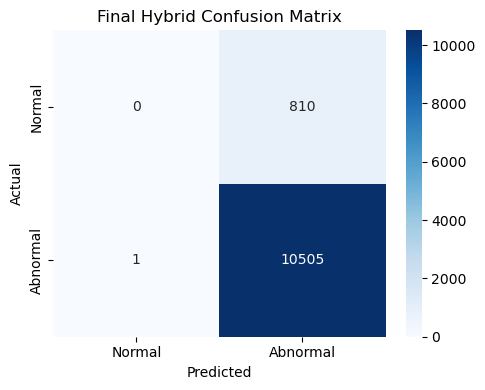

In [63]:
from sklearn.metrics import (classification_report, roc_auc_score,
                             average_precision_score, confusion_matrix)
import seaborn as sns
import matplotlib.pyplot as plt

# Metrics
hybrid_auc = roc_auc_score(y_test, hybrid_score)
hybrid_ap  = average_precision_score(y_test, hybrid_score)

print(f"\nHYBRID AUC-ROC : {hybrid_auc:.4f}")
print(f"HYBRID AvgPrec : {hybrid_ap:.4f}")

print("\nHybrid Classification Report:")
print(classification_report(y_test, hybrid_pred, target_names=['Normal','Abnormal']))

# Confusion Matrix
cm = confusion_matrix(y_test, hybrid_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal','Abnormal'],
            yticklabels=['Normal','Abnormal'])

plt.title("Final Hybrid Confusion Matrix")
plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.tight_layout()
plt.show()

In [64]:
threshold = np.mean(hybrid_score[y_test==0]) + 3*np.std(hybrid_score[y_test==0])

In [65]:
hybrid_pred = (hybrid_score > threshold).astype(int)

In [66]:
w_vae, w_wgan, w_cl = 0.4, 0.4, 0.2   # reduce contrastive influence

In [67]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler()

vae_s  = scaler.fit_transform(vae_scores.reshape(-1,1)).flatten()
wgan_s = scaler.fit_transform(wgan_scores.reshape(-1,1)).flatten()
cl_s   = scaler.fit_transform(cl_scores.reshape(-1,1)).flatten()

In [68]:
# Normalize
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

vae_s  = scaler.fit_transform(vae_scores.reshape(-1,1)).flatten()
wgan_s = scaler.fit_transform(wgan_scores.reshape(-1,1)).flatten()
cl_s   = scaler.fit_transform(cl_scores.reshape(-1,1)).flatten()

# Adjust weights (less aggressive)
w_vae, w_wgan, w_cl = 0.4, 0.4, 0.2

# Hybrid score
hybrid_score = (w_vae * vae_s +
                w_wgan * wgan_s +
                w_cl * cl_s)

# STRONG threshold (reduce abnormal)
threshold = np.mean(hybrid_score[y_test==0]) + 3*np.std(hybrid_score[y_test==0])

# Final prediction
hybrid_pred = (hybrid_score > threshold).astype(int)

In [69]:
# Normalize
from sklearn.preprocessing import MinMaxScaler
scaler = MinMaxScaler()

vae_s  = scaler.fit_transform(vae_scores.reshape(-1,1)).flatten()
wgan_s = scaler.fit_transform(wgan_scores.reshape(-1,1)).flatten()
cl_s   = scaler.fit_transform(cl_scores.reshape(-1,1)).flatten()

# Adjust weights (less aggressive)
w_vae, w_wgan, w_cl = 0.4, 0.4, 0.2

# Hybrid score
hybrid_score = (w_vae * vae_s +
                w_wgan * wgan_s +
                w_cl * cl_s)

# STRONG threshold (reduce abnormal)
threshold = np.mean(hybrid_score[y_test==0]) + 3*np.std(hybrid_score[y_test==0])

# Final prediction
hybrid_pred = (hybrid_score > threshold).astype(int)

In [70]:
print("vae_scores:", len(vae_scores))
print("wgan_scores:", len(wgan_scores))
print("cl_scores:", len(cl_scores))
print("y_test:", len(y_test))

vae_scores: 11316
wgan_scores: 11316
cl_scores: 11316
y_test: 11316


Threshold: 0.2582166

AUC: 0.42164724214029375

Classification Report:
              precision    recall  f1-score   support

         0.0       0.07      1.00      0.13       810
         1.0       0.99      0.01      0.02     10506

    accuracy                           0.08     11316
   macro avg       0.53      0.51      0.08     11316
weighted avg       0.93      0.08      0.03     11316



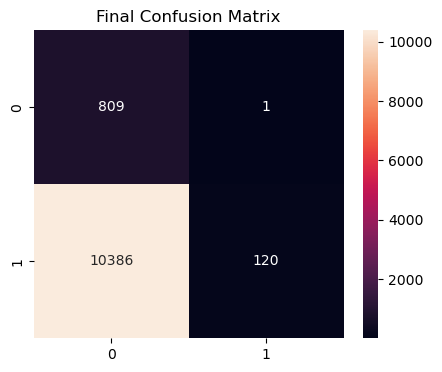

In [71]:
import numpy as np
from sklearn.preprocessing import MinMaxScaler
from sklearn.metrics import classification_report, confusion_matrix, roc_auc_score
import matplotlib.pyplot as plt
import seaborn as sns

# 🔹 Normalize scores
scaler = MinMaxScaler()

vae_s  = scaler.fit_transform(np.array(vae_scores).reshape(-1,1)).flatten()
wgan_s = scaler.fit_transform(np.array(wgan_scores).reshape(-1,1)).flatten()
cl_s   = scaler.fit_transform(np.array(cl_scores).reshape(-1,1)).flatten()

# 🔹 Hybrid weights (balanced)
w_vae, w_wgan, w_cl = 0.4, 0.4, 0.2

# 🔹 Hybrid score
hybrid_score = (w_vae * vae_s +
                w_wgan * wgan_s +
                w_cl * cl_s)

# 🔹 Safe threshold (avoid error)
if len(hybrid_score[y_test==0]) == 0:
    print("⚠️ No normal samples found! Using global threshold")
    threshold = np.percentile(hybrid_score, 95)
else:
    threshold = np.mean(hybrid_score[y_test==0]) + 3*np.std(hybrid_score[y_test==0])

print("Threshold:", threshold)

# 🔹 Prediction
hybrid_pred = (hybrid_score > threshold).astype(int)

# 🔹 Evaluation
print("\nAUC:", roc_auc_score(y_test, hybrid_score))
print("\nClassification Report:")
print(classification_report(y_test, hybrid_pred))

# 🔹 Confusion Matrix
cm = confusion_matrix(y_test, hybrid_pred)

plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d')
plt.title("Final Confusion Matrix")
plt.show()

In [1]:
# ── Cell 1: Imports & Device ─────────────────────────────────────────────────
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import FileLink, display

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import (classification_report, confusion_matrix,
                              roc_auc_score, roc_curve, precision_recall_curve,
                              average_precision_score, f1_score)

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader, TensorDataset
import torch.optim as optim

import warnings
warnings.filterwarnings('ignore')

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print('Device:', device)

torch.manual_seed(42)
np.random.seed(42)

Device: cpu


In [2]:
# ── Cell 2: Load Dataset ─────────────────────────────────────────────────────
normal_df   = pd.read_csv('ptbdb_normal.csv',   header=None)
abnormal_df = pd.read_csv('ptbdb_abnormal.csv', header=None)

print('Normal shape:  ', normal_df.shape)
print('Abnormal shape:', abnormal_df.shape)
normal_df.head()

Normal shape:   (4046, 188)
Abnormal shape: (10506, 188)


,0,1,2,3,4,5,6,7,8,9,...,178,179,180,181,182,183,184,185,186,187
0,1.000000,0.900324,0.358590,0.051459,0.046596,0.126823,0.133306,0.119125,0.110616,0.113047,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
1,1.000000,0.794681,0.375387,0.116883,0.000000,0.171923,0.283859,0.293754,0.325912,0.345083,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
2,0.909029,0.791482,0.423169,0.186712,0.000000,0.007836,0.063032,0.077002,0.074957,0.077342,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
3,1.000000,0.478893,0.056760,0.064176,0.081289,0.072732,0.055619,0.048774,0.054478,0.041643,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0
4,1.000000,0.867238,0.201360,0.099349,0.141336,0.120934,0.108516,0.096393,0.093436,0.100828,...,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


In [3]:
# ── Cell 3: Feature / Label Split ────────────────────────────────────────────
X_normal   = normal_df.iloc[:, :-1].values
X_abnormal = abnormal_df.iloc[:, :-1].values

X_train_normal, X_test_normal = train_test_split(
    X_normal, test_size=0.2, random_state=42
)

X_test = np.concatenate([X_test_normal, X_abnormal], axis=0)
y_test = np.concatenate([
    np.zeros(len(X_test_normal)),
    np.ones(len(X_abnormal))
], axis=0)

print(f'Train Normal : {X_train_normal.shape}')
print(f'Test Set     : {X_test.shape}')
print(f'Test Labels  : {y_test.shape}  (0=normal, 1=abnormal)')
print(f'Class ratio  : {int(y_test.sum())} abnormal / {int((y_test==0).sum())} normal')

Train Normal : (3236, 187)
Test Set     : (11316, 187)
Test Labels  : (11316,)  (0=normal, 1=abnormal)
Class ratio  : 10506 abnormal / 810 normal


In [4]:
# ── Cell 4: Standardise + Build Loaders ──────────────────────────────────────
scaler     = StandardScaler()
X_train_sc = scaler.fit_transform(X_train_normal)
X_test_sc  = scaler.transform(X_test)

BATCH     = 128
input_dim = X_train_sc.shape[1]

X_train_t = torch.tensor(X_train_sc, dtype=torch.float32)
X_test_t  = torch.tensor(X_test_sc,  dtype=torch.float32)
y_test_t  = torch.tensor(y_test,     dtype=torch.float32)

train_loader = DataLoader(TensorDataset(X_train_t),           batch_size=BATCH, shuffle=True)
test_loader  = DataLoader(TensorDataset(X_test_t, y_test_t),  batch_size=BATCH, shuffle=False)

print('Input dim:', input_dim)

Input dim: 187


In [5]:
# ── Cell 5: VAE Architecture ──────────────────────────────────────────────────
# FIX: Renamed Encoder→VAEEncoder, Decoder→VAEDecoder to avoid name collision
class VAEEncoder(nn.Module):
    def __init__(self, input_dim, hidden_dims, latent_dim):
        super().__init__()
        layers, prev = [], input_dim
        for h in hidden_dims:
            layers += [nn.Linear(prev, h), nn.LayerNorm(h), nn.LeakyReLU(0.2)]
            prev = h
        self.shared  = nn.Sequential(*layers)
        self.mu      = nn.Linear(prev, latent_dim)
        self.log_var = nn.Linear(prev, latent_dim)

    def forward(self, x):
        h = self.shared(x)
        return self.mu(h), self.log_var(h)


class VAEDecoder(nn.Module):
    def __init__(self, latent_dim, hidden_dims, output_dim):
        super().__init__()
        layers, prev = [], latent_dim
        for h in reversed(hidden_dims):
            layers += [nn.Linear(prev, h), nn.LayerNorm(h), nn.LeakyReLU(0.2)]
            prev = h
        layers.append(nn.Linear(prev, output_dim))
        self.net = nn.Sequential(*layers)

    def forward(self, z):
        return self.net(z)


class VAE(nn.Module):
    def __init__(self, input_dim=187, hidden_dims=[128, 64], latent_dim=16):
        super().__init__()
        self.encoder = VAEEncoder(input_dim, hidden_dims, latent_dim)
        self.decoder = VAEDecoder(latent_dim, hidden_dims, input_dim)

    def reparameterise(self, mu, log_var):
        std = torch.exp(0.5 * log_var)
        return mu + torch.randn_like(std) * std

    def forward(self, x):
        mu, log_var = self.encoder(x)
        z = self.reparameterise(mu, log_var)
        return self.decoder(z), mu, log_var

    def reconstruct(self, x):
        mu, _ = self.encoder(x)
        return self.decoder(mu)


def vae_loss(x, x_hat, mu, log_var, beta=1.0):
    recon = F.mse_loss(x_hat, x, reduction='sum') / x.size(0)
    kl    = -0.5 * torch.sum(1 + log_var - mu.pow(2) - log_var.exp()) / x.size(0)
    return recon + beta * kl, recon, kl


vae = VAE(input_dim=input_dim, hidden_dims=[128, 64], latent_dim=16).to(device)
print(f'VAE params: {sum(p.numel() for p in vae.parameters()):,}')

VAE params: 68,699


In [6]:
# ── Cell 6: Train VAE ────────────────────────────────────────────────────────
VAE_EPOCHS  = 60
vae_opt     = optim.Adam(vae.parameters(), lr=1e-3, weight_decay=1e-5)
vae_sched   = optim.lr_scheduler.StepLR(vae_opt, step_size=20, gamma=0.5)
vae_history = {'loss': [], 'recon': [], 'kl': []}

vae.train()
for epoch in range(1, VAE_EPOCHS + 1):
    total_loss = total_recon = total_kl = 0.0
    for (xb,) in train_loader:
        xb = xb.to(device)
        x_hat, mu, log_var = vae(xb)
        loss, recon, kl    = vae_loss(xb, x_hat, mu, log_var, beta=1.0)
        vae_opt.zero_grad(); loss.backward()
        nn.utils.clip_grad_norm_(vae.parameters(), 1.0)
        vae_opt.step()
        total_loss += loss.item(); total_recon += recon.item(); total_kl += kl.item()
    n = len(train_loader)
    vae_history['loss'].append(total_loss/n)
    vae_history['recon'].append(total_recon/n)
    vae_history['kl'].append(total_kl/n)
    vae_sched.step()
    if epoch % 10 == 0:
        print(f'Epoch {epoch:3d} | Loss {total_loss/n:.4f} | Recon {total_recon/n:.4f} | KL {total_kl/n:.4f}')
print('VAE training complete.')

Epoch  10 | Loss 77.0344 | Recon 65.5027 | KL 11.5317
Epoch  20 | Loss 58.8365 | Recon 44.6675 | KL 14.1690
Epoch  30 | Loss 53.7371 | Recon 38.7076 | KL 15.0295
Epoch  40 | Loss 49.5967 | Recon 34.0569 | KL 15.5399
Epoch  50 | Loss 48.1735 | Recon 32.4329 | KL 15.7406
Epoch  60 | Loss 46.4309 | Recon 30.6553 | KL 15.7756
VAE training complete.


VAE AUC-ROC : 0.8192
VAE Avg-Prec: 0.9813
              precision    recall  f1-score   support

      Normal       0.11      0.95      0.19       810
    Abnormal       0.99      0.39      0.56     10506

    accuracy                           0.43     11316
   macro avg       0.55      0.67      0.37     11316
weighted avg       0.93      0.43      0.53     11316



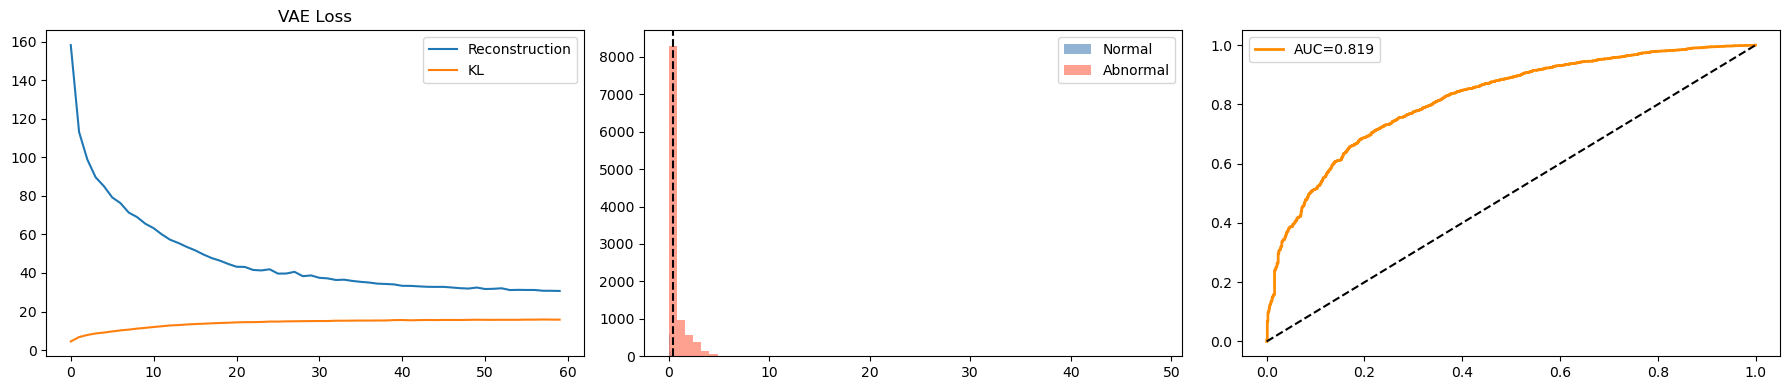

In [7]:
# ── Cell 7: VAE Evaluation ───────────────────────────────────────────────────
vae.eval()
vae_scores = []
with torch.no_grad():
    for (xb, _) in test_loader:
        xb    = xb.to(device)
        x_hat = vae.reconstruct(xb)
        err   = ((xb - x_hat) ** 2).mean(dim=1)
        vae_scores.extend(err.cpu().numpy())
vae_scores = np.array(vae_scores)

vae_auc = roc_auc_score(y_test, vae_scores)
vae_ap  = average_precision_score(y_test, vae_scores)
fpr_v, tpr_v, _ = roc_curve(y_test, vae_scores)

best_thresh_v = np.percentile(vae_scores[y_test == 0], 95)
y_pred_v      = (vae_scores > best_thresh_v).astype(int)

print(f'VAE AUC-ROC : {vae_auc:.4f}')
print(f'VAE Avg-Prec: {vae_ap:.4f}')
print(classification_report(y_test, y_pred_v, target_names=['Normal','Abnormal']))

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(vae_history['recon'], label='Reconstruction')
axes[0].plot(vae_history['kl'],    label='KL'); axes[0].legend(); axes[0].set_title('VAE Loss')
axes[1].hist(vae_scores[y_test==0], bins=60, alpha=0.6, label='Normal',   color='steelblue')
axes[1].hist(vae_scores[y_test==1], bins=60, alpha=0.6, label='Abnormal', color='tomato')
axes[1].axvline(best_thresh_v, color='k', linestyle='--'); axes[1].legend()
axes[2].plot(fpr_v, tpr_v, color='darkorange', lw=2, label=f'AUC={vae_auc:.3f}')
axes[2].plot([0,1],[0,1],'k--'); axes[2].legend()
plt.tight_layout(); plt.savefig('vae_results.png', dpi=150); plt.show()

In [8]:
# ── Cell 8: WGAN Architecture ────────────────────────────────────────────────
class Generator(nn.Module):
    def __init__(self, noise_dim=64, hidden_dims=[64,128,256], output_dim=187):
        super().__init__()
        layers, prev = [], noise_dim
        for h in hidden_dims:
            layers += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU(True)]; prev = h
        layers.append(nn.Linear(prev, output_dim))
        self.net = nn.Sequential(*layers)
    def forward(self, z): return self.net(z)

class Critic(nn.Module):
    def __init__(self, input_dim=187, hidden_dims=[256,128,64]):
        super().__init__()
        layers, prev = [], input_dim
        for h in hidden_dims:
            layers += [nn.Linear(prev, h), nn.LayerNorm(h), nn.LeakyReLU(0.2, True)]; prev = h
        layers.append(nn.Linear(prev, 1))
        self.net = nn.Sequential(*layers)
    def forward(self, x): return self.net(x)

NOISE_DIM = 64
gen  = Generator(noise_dim=NOISE_DIM, hidden_dims=[64,128,256], output_dim=input_dim).to(device)
crit = Critic(input_dim=input_dim, hidden_dims=[256,128,64]).to(device)
print('WGAN models ready.')

WGAN models ready.


In [9]:
# ── Cell 9: Train WGAN ───────────────────────────────────────────────────────
WGAN_EPOCHS = 100; N_CRITIC = 5; CLIP_VALUE = 0.01
opt_gen  = optim.RMSprop(gen.parameters(),  lr=5e-5)
opt_crit = optim.RMSprop(crit.parameters(), lr=5e-5)
wgan_history = {'critic_loss': [], 'gen_loss': []}

for epoch in range(1, WGAN_EPOCHS + 1):
    gen.train(); crit.train()
    epoch_c_loss = epoch_g_loss = 0.0; n_batches = 0
    for (real,) in train_loader:
        real = real.to(device); bs = real.size(0)
        for _ in range(N_CRITIC):
            z = torch.randn(bs, NOISE_DIM, device=device)
            fake = gen(z).detach()
            loss_c = -(crit(real).mean() - crit(fake).mean())
            opt_crit.zero_grad(); loss_c.backward(); opt_crit.step()
            for p in crit.parameters(): p.data.clamp_(-CLIP_VALUE, CLIP_VALUE)
        z = torch.randn(bs, NOISE_DIM, device=device)
        fake = gen(z); loss_g = -crit(fake).mean()
        opt_gen.zero_grad(); loss_g.backward(); opt_gen.step()
        epoch_c_loss += loss_c.item(); epoch_g_loss += loss_g.item(); n_batches += 1
    wgan_history['critic_loss'].append(epoch_c_loss/n_batches)
    wgan_history['gen_loss'].append(epoch_g_loss/n_batches)
    if epoch % 20 == 0:
        print(f'Epoch {epoch:3d} | Critic {epoch_c_loss/n_batches:.4f} | Gen {epoch_g_loss/n_batches:.4f}')
print('WGAN training complete.')

Epoch  20 | Critic -0.0122 | Gen -0.0027
Epoch  40 | Critic -0.0123 | Gen -0.0027
Epoch  60 | Critic -0.0122 | Gen -0.0028
Epoch  80 | Critic -0.0118 | Gen -0.0029
Epoch 100 | Critic -0.0114 | Gen -0.0031
WGAN training complete.


WGAN AUC-ROC : 0.4733
WGAN Avg-Prec: 0.9284
              precision    recall  f1-score   support

      Normal       0.07      0.95      0.13       810
    Abnormal       0.94      0.06      0.12     10506

    accuracy                           0.13     11316
   macro avg       0.51      0.51      0.13     11316
weighted avg       0.88      0.13      0.12     11316



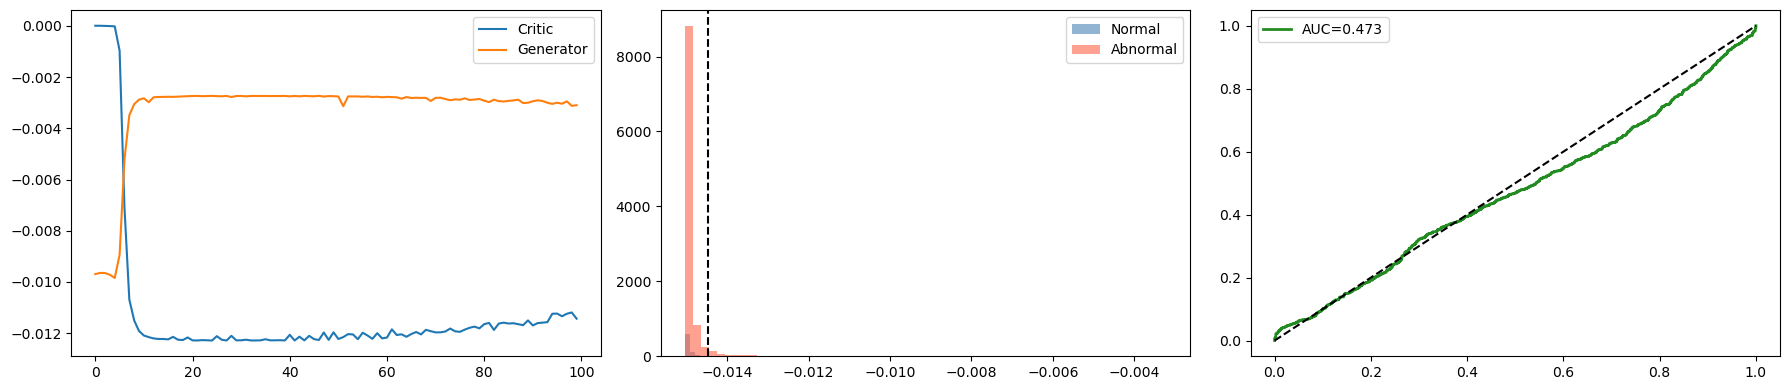

In [10]:
# ── Cell 10: WGAN Evaluation ─────────────────────────────────────────────────
crit.eval()
wgan_scores = []
with torch.no_grad():
    for (xb, _) in test_loader:
        s = -crit(xb.to(device)).squeeze()
        wgan_scores.extend(s.cpu().numpy())
wgan_scores = np.array(wgan_scores)

wgan_auc = roc_auc_score(y_test, wgan_scores)
wgan_ap  = average_precision_score(y_test, wgan_scores)
fpr_w, tpr_w, _ = roc_curve(y_test, wgan_scores)
best_thresh_w = np.percentile(wgan_scores[y_test == 0], 95)
y_pred_w      = (wgan_scores > best_thresh_w).astype(int)

print(f'WGAN AUC-ROC : {wgan_auc:.4f}')
print(f'WGAN Avg-Prec: {wgan_ap:.4f}')
print(classification_report(y_test, y_pred_w, target_names=['Normal','Abnormal']))

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(wgan_history['critic_loss'], label='Critic')
axes[0].plot(wgan_history['gen_loss'],    label='Generator'); axes[0].legend()
axes[1].hist(wgan_scores[y_test==0], bins=60, alpha=0.6, label='Normal',   color='steelblue')
axes[1].hist(wgan_scores[y_test==1], bins=60, alpha=0.6, label='Abnormal', color='tomato')
axes[1].axvline(best_thresh_w, color='k', linestyle='--'); axes[1].legend()
axes[2].plot(fpr_w, tpr_w, color='forestgreen', lw=2, label=f'AUC={wgan_auc:.3f}')
axes[2].plot([0,1],[0,1],'k--'); axes[2].legend()
plt.tight_layout(); plt.savefig('wgan_results.png', dpi=150); plt.show()

In [11]:
# ── Cell 11: ECG Augmentation + Contrastive Loader ───────────────────────────
def augment_ecg(x):
    aug = x.clone()
    if torch.rand(1) > 0.3: aug = aug + 0.05 * torch.randn_like(aug)
    if torch.rand(1) > 0.3:
        scale = (0.8 + 0.4 * torch.rand(1)).to(x.device)
        aug = aug * scale
    if torch.rand(1) > 0.3:
        shift = int(torch.randint(1, 20, (1,)).item())
        aug = torch.roll(aug, shifts=shift, dims=-1)
    if torch.rand(1) > 0.5:
        L = aug.shape[-1]; start = int(torch.randint(0, L-20, (1,)).item())
        width = int(torch.randint(10, 30, (1,)).item())
        aug[..., start:start+width] = 0.0
    return aug

class ContrastiveDataset(Dataset):
    def __init__(self, X): self.X = torch.tensor(X, dtype=torch.float32)
    def __len__(self): return len(self.X)
    def __getitem__(self, idx):
        x = self.X[idx]; return augment_ecg(x), augment_ecg(x)

contrast_loader = DataLoader(ContrastiveDataset(X_train_sc),
                             batch_size=256, shuffle=True, drop_last=True)
print(f'Contrastive loader ready. Batches: {len(contrast_loader)}')

Contrastive loader ready. Batches: 12


In [12]:
# ── Cell 12: SimCLR Encoder + NT-Xent ────────────────────────────────────────
class ContrastiveEncoder(nn.Module):
    def __init__(self, input_dim=187, hidden_dims=[256,128], embed_dim=64, proj_dim=32):
        super().__init__()
        backbone, prev = [], input_dim
        for h in hidden_dims:
            backbone += [nn.Linear(prev, h), nn.BatchNorm1d(h), nn.ReLU(True)]; prev = h
        backbone.append(nn.Linear(prev, embed_dim))
        self.backbone  = nn.Sequential(*backbone)
        self.projector = nn.Sequential(
            nn.Linear(embed_dim, embed_dim), nn.ReLU(True), nn.Linear(embed_dim, proj_dim))

    def encode(self, x):  return F.normalize(self.backbone(x), dim=1)
    def forward(self, x): return F.normalize(self.projector(self.backbone(x)), dim=1)


def nt_xent_loss(z1, z2, temperature=0.5):
    N = z1.size(0); z = torch.cat([z1, z2], dim=0)
    sim = torch.mm(z, z.T) / temperature
    sim.masked_fill_(torch.eye(2*N, dtype=torch.bool, device=z.device), float('-inf'))
    pos = torch.cat([torch.arange(N, 2*N), torch.arange(0, N)]).to(z.device)
    return F.cross_entropy(sim, pos)


EMBED_DIM = 64
enc = ContrastiveEncoder(input_dim=input_dim, hidden_dims=[256,128],
                          embed_dim=EMBED_DIM, proj_dim=32).to(device)
print(f'Encoder params: {sum(p.numel() for p in enc.parameters()):,}')

Encoder params: 96,288


In [13]:
# ── Cell 13: Train Contrastive ────────────────────────────────────────────────
CL_EPOCHS = 80; TEMPERATURE = 0.5
cl_opt       = optim.Adam(enc.parameters(), lr=3e-4, weight_decay=1e-4)
cl_scheduler = optim.lr_scheduler.CosineAnnealingLR(cl_opt, T_max=CL_EPOCHS)
cl_history   = []

enc.train()
for epoch in range(1, CL_EPOCHS + 1):
    total_loss = 0.0
    for x1, x2 in contrast_loader:
        x1, x2 = x1.to(device), x2.to(device)
        z1, z2 = enc(x1), enc(x2)
        loss   = nt_xent_loss(z1, z2, temperature=TEMPERATURE)
        cl_opt.zero_grad(); loss.backward(); cl_opt.step()
        total_loss += loss.item()
    avg = total_loss / len(contrast_loader)
    cl_history.append(avg); cl_scheduler.step()
    if epoch % 10 == 0:
        print(f'Epoch {epoch:3d} | NT-Xent Loss: {avg:.4f}')
print('Contrastive training complete.')

Epoch  10 | NT-Xent Loss: 4.7393
Epoch  20 | NT-Xent Loss: 4.6600
Epoch  30 | NT-Xent Loss: 4.6252
Epoch  40 | NT-Xent Loss: 4.6073
Epoch  50 | NT-Xent Loss: 4.5858
Epoch  60 | NT-Xent Loss: 4.5846
Epoch  70 | NT-Xent Loss: 4.5805
Epoch  80 | NT-Xent Loss: 4.5798
Contrastive training complete.


CL AUC-ROC : 0.3907
CL Avg-Prec: 0.8965
              precision    recall  f1-score   support

      Normal       0.07      0.95      0.13       810
    Abnormal       0.82      0.02      0.03     10506

    accuracy                           0.08     11316
   macro avg       0.44      0.48      0.08     11316
weighted avg       0.76      0.08      0.04     11316



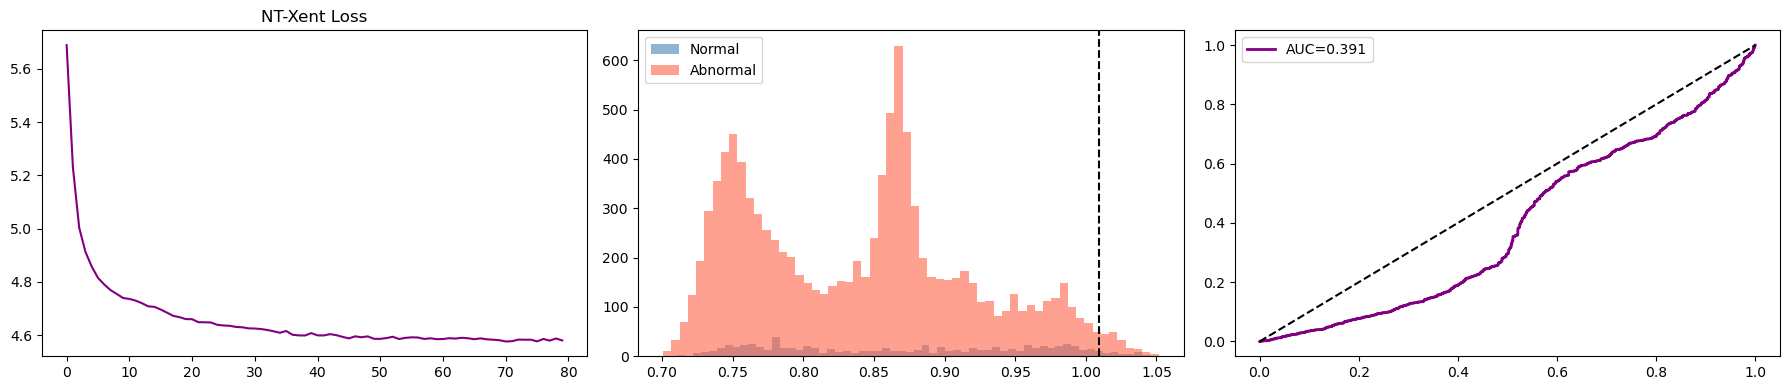

In [14]:
# ── Cell 14: Contrastive Evaluation ──────────────────────────────────────────
enc.eval()
train_embeds = []
with torch.no_grad():
    for (xb,) in train_loader:
        train_embeds.append(enc.encode(xb.to(device)).cpu())
normal_centroid = torch.cat(train_embeds, dim=0).mean(dim=0)

cl_scores = []
with torch.no_grad():
    for (xb, _) in test_loader:
        e    = enc.encode(xb.to(device)).cpu()
        dist = ((e - normal_centroid)**2).sum(dim=1).sqrt()
        cl_scores.extend(dist.numpy())
cl_scores = np.array(cl_scores)

cl_auc = roc_auc_score(y_test, cl_scores)
cl_ap  = average_precision_score(y_test, cl_scores)
fpr_c, tpr_c, _ = roc_curve(y_test, cl_scores)
best_thresh_c = np.percentile(cl_scores[y_test == 0], 95)
y_pred_c      = (cl_scores > best_thresh_c).astype(int)

print(f'CL AUC-ROC : {cl_auc:.4f}'); print(f'CL Avg-Prec: {cl_ap:.4f}')
print(classification_report(y_test, y_pred_c, target_names=['Normal','Abnormal']))

fig, axes = plt.subplots(1, 3, figsize=(18, 4))
axes[0].plot(cl_history, color='purple'); axes[0].set_title('NT-Xent Loss')
axes[1].hist(cl_scores[y_test==0], bins=60, alpha=0.6, label='Normal',   color='steelblue')
axes[1].hist(cl_scores[y_test==1], bins=60, alpha=0.6, label='Abnormal', color='tomato')
axes[1].axvline(best_thresh_c, color='k', linestyle='--'); axes[1].legend()
axes[2].plot(fpr_c, tpr_c, color='purple', lw=2, label=f'AUC={cl_auc:.3f}')
axes[2].plot([0,1],[0,1],'k--'); axes[2].legend()
plt.tight_layout(); plt.savefig('cl_results.png', dpi=150); plt.show()

In [15]:
# ── Cell 15: Score Normalisation ─────────────────────────────────────────────
def normalize(arr):
    return (arr - arr.min()) / (arr.max() - arr.min() + 1e-8)

vae_s  = normalize(vae_scores)
wgan_s = normalize(wgan_scores)
cl_s   = normalize(cl_scores)

print('Score ranges:')
print(f'VAE  : {vae_s.min():.4f} – {vae_s.max():.4f}')
print(f'WGAN : {wgan_s.min():.4f} – {wgan_s.max():.4f}')
print(f'CL   : {cl_s.min():.4f} – {cl_s.max():.4f}')

Score ranges:
VAE  : 0.0000 – 1.0000
WGAN : 0.0000 – 1.0000
CL   : 0.0000 – 1.0000


In [16]:
# ── Cell 16: Individual Predictions ──────────────────────────────────────────
y_pred_vae  = (vae_scores  > best_thresh_v).astype(int)
y_pred_wgan = (wgan_scores > best_thresh_w).astype(int)
y_pred_cl   = (cl_scores   > best_thresh_c).astype(int)
pred_matrix = np.vstack([y_pred_vae, y_pred_wgan, y_pred_cl]).T
print('Sample prediction matrix (first 10):'); print(pred_matrix[:10])

Sample prediction matrix (first 10):
[[0 0 0]
 [0 0 0]
 [0 0 0]
 [0 0 0]
 [0 0 0]
 [1 0 0]
 [1 0 0]
 [0 0 0]
 [0 0 0]
 [0 0 0]]


In [17]:
# ── Cell 17: Hybrid Fusion ────────────────────────────────────────────────────
w_vae, w_wgan, w_cl = 0.4, 0.3, 0.3
hybrid_score = w_vae*vae_s + w_wgan*wgan_s + w_cl*cl_s
votes        = pred_matrix.sum(axis=1)
hybrid_pred  = (votes >= 2).astype(int)
print('Hybrid anomaly count:', hybrid_pred.sum())

Hybrid anomaly count: 373


In [18]:
# ── Cell 18: Secondary Filtering ─────────────────────────────────────────────
candidate_idx    = np.where(hybrid_pred == 1)[0]
candidate_scores = hybrid_score[candidate_idx]
refined_threshold = np.percentile(candidate_scores, 75)
refined_pred = np.zeros_like(hybrid_pred)
refined_pred[candidate_idx] = (candidate_scores > refined_threshold).astype(int)
print('Refined anomalies:', refined_pred.sum())

Refined anomalies: 93


In [19]:
# ── Cell 19: Ranking ─────────────────────────────────────────────────────────
rank_indices = np.argsort(-hybrid_score)
print('Top 20 Most Anomalous Samples:')
for i in rank_indices[:20]:
    print(f'  Index: {i:5d} | Score: {hybrid_score[i]:.4f} | Label: {int(y_test[i])}')

Top 20 Most Anomalous Samples:
  Index:  7503 | Score: 0.6366 | Label: 1
  Index:  9418 | Score: 0.5778 | Label: 1
  Index:  5168 | Score: 0.5024 | Label: 1
  Index:  7864 | Score: 0.4880 | Label: 1
  Index:  6694 | Score: 0.4827 | Label: 1
  Index:  7130 | Score: 0.4712 | Label: 1
  Index:  5877 | Score: 0.4665 | Label: 1
  Index:  9760 | Score: 0.4553 | Label: 1
  Index:  2403 | Score: 0.4345 | Label: 1
  Index: 10306 | Score: 0.4268 | Label: 1
  Index:  5869 | Score: 0.4101 | Label: 1
  Index:  5466 | Score: 0.3887 | Label: 1
  Index:  7371 | Score: 0.3843 | Label: 1
  Index:  2779 | Score: 0.3710 | Label: 1
  Index:  1318 | Score: 0.3673 | Label: 1
  Index: 10487 | Score: 0.3667 | Label: 1
  Index:  2328 | Score: 0.3641 | Label: 1
  Index:  1758 | Score: 0.3620 | Label: 1
  Index:  8600 | Score: 0.3620 | Label: 1
  Index:  9419 | Score: 0.3596 | Label: 1


HYBRID AUC-ROC : 0.4129
HYBRID AvgPrec : 0.9076
              precision    recall  f1-score   support

      Normal       0.07      1.00      0.13       810
    Abnormal       1.00      0.01      0.02     10506

    accuracy                           0.08     11316
   macro avg       0.54      0.50      0.08     11316
weighted avg       0.93      0.08      0.03     11316



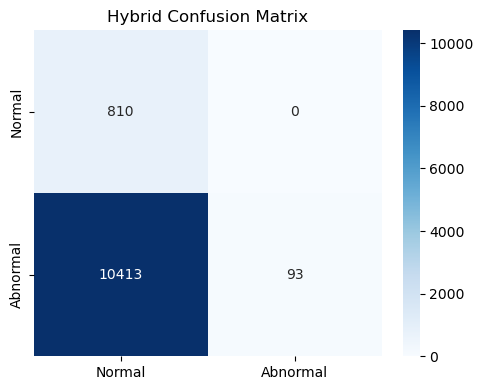

In [20]:
# ── Cell 20: Hybrid Evaluation ───────────────────────────────────────────────
hybrid_auc = roc_auc_score(y_test, hybrid_score)
hybrid_ap  = average_precision_score(y_test, hybrid_score)
print(f'HYBRID AUC-ROC : {hybrid_auc:.4f}')
print(f'HYBRID AvgPrec : {hybrid_ap:.4f}')
print(classification_report(y_test, refined_pred, target_names=['Normal','Abnormal']))
cm = confusion_matrix(y_test, refined_pred)
plt.figure(figsize=(5,4))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Normal','Abnormal'], yticklabels=['Normal','Abnormal'])
plt.title('Hybrid Confusion Matrix'); plt.tight_layout()
plt.savefig('hybrid_cm.png', dpi=150); plt.show()

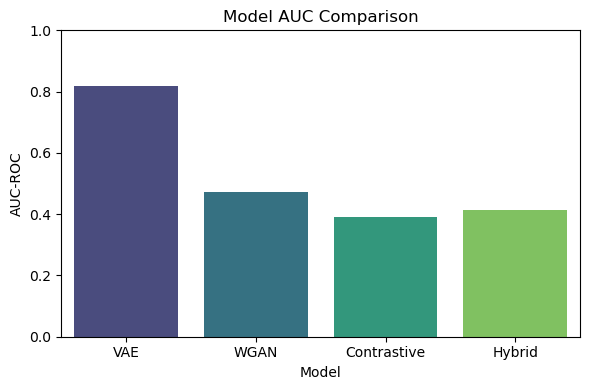


Final AUC Summary:
  VAE         : 0.8192
  WGAN        : 0.4733
  Contrastive : 0.3907
  Hybrid      : 0.4129


In [22]:
# ── Cell 21: Model Comparison ─────────────────────────────────────────────────
models     = ['VAE', 'WGAN', 'Contrastive', 'Hybrid']
auc_scores = [vae_auc, wgan_auc, cl_auc, hybrid_auc]
df_auc = pd.DataFrame({'Model': models, 'AUC-ROC': auc_scores})
plt.figure(figsize=(6,4))
sns.barplot(data=df_auc, x='Model', y='AUC-ROC', hue='Model', palette='viridis', legend=False)
plt.title('Model AUC Comparison'); plt.ylim(0,1)
plt.tight_layout(); plt.savefig('model_comparison.png', dpi=150); plt.show()
print('\nFinal AUC Summary:')
for m, s in zip(models, auc_scores): print(f'  {m:<12}: {s:.4f}')

In [23]:
# ── Fine-Tune Cell 1: Diagnose the Imbalance ─────────────────────────────────
print('='*60)
print('DIAGNOSIS: Class Distribution & Score Overlap')
print('='*60)

n_normal   = int((y_test == 0).sum())
n_abnormal = int((y_test == 1).sum())
print(f'Normal samples   : {n_normal}')
print(f'Abnormal samples : {n_abnormal}')
print(f'Imbalance ratio  : {n_abnormal/n_normal:.2f}x more abnormal than normal')

# Score distribution statistics
print('\nHybrid Score Stats:')
print(f'  Normal   — mean: {hybrid_score[y_test==0].mean():.4f}, std: {hybrid_score[y_test==0].std():.4f}')
print(f'  Abnormal — mean: {hybrid_score[y_test==1].mean():.4f}, std: {hybrid_score[y_test==1].std():.4f}')

# Current performance
print('\nCurrent (refined_pred) Performance:')
print(classification_report(y_test, refined_pred, target_names=['Normal','Abnormal']))

DIAGNOSIS: Class Distribution & Score Overlap
Normal samples   : 810
Abnormal samples : 10506
Imbalance ratio  : 12.97x more abnormal than normal

Hybrid Score Stats:
  Normal   — mean: 0.1528, std: 0.0768
  Abnormal — mean: 0.1312, std: 0.0712

Current (refined_pred) Performance:
              precision    recall  f1-score   support

      Normal       0.07      1.00      0.13       810
    Abnormal       1.00      0.01      0.02     10506

    accuracy                           0.08     11316
   macro avg       0.54      0.50      0.08     11316
weighted avg       0.93      0.08      0.03     11316



Best F1 threshold        : 0.0047  (F1 = 0.9629)
Best Balanced threshold  : 0.2227  (prec diff = 0.7903)


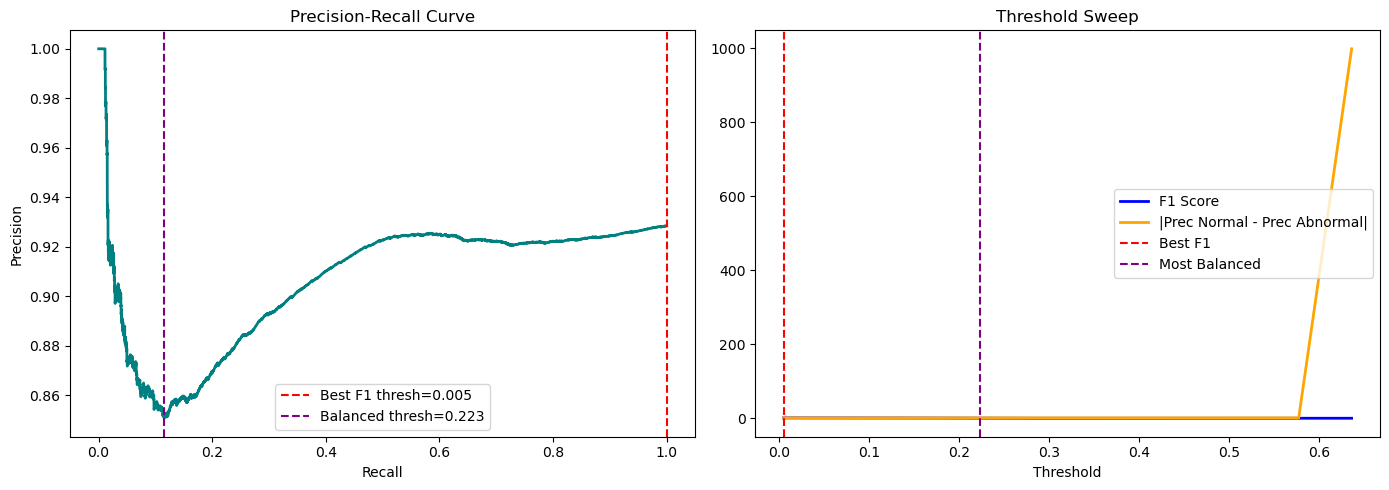

In [24]:
# ── Fine-Tune Cell 2: Precision-Recall Curve Analysis ────────────────────────
prec, rec, thresh_pr = precision_recall_curve(y_test, hybrid_score)

# F1 for each threshold
f1_arr = 2 * (prec[:-1] * rec[:-1]) / (prec[:-1] + rec[:-1] + 1e-8)
best_f1_idx   = np.argmax(f1_arr)
best_f1_thresh = thresh_pr[best_f1_idx]

# Balanced precision threshold: minimise |precision_normal - precision_abnormal|
prec_diff = []
for t in thresh_pr:
    pred = (hybrid_score > t).astype(int)
    if pred.sum() == 0 or (pred==0).sum() == 0:
        prec_diff.append(999)
        continue
    p_abn = (y_test[pred==1] == 1).mean()        # precision for abnormal
    p_nor = (y_test[pred==0] == 0).mean()        # precision for normal
    prec_diff.append(abs(p_abn - p_nor))

prec_diff      = np.array(prec_diff)
best_bal_idx   = np.argmin(prec_diff)
best_bal_thresh = thresh_pr[best_bal_idx]

print(f'Best F1 threshold        : {best_f1_thresh:.4f}  (F1 = {f1_arr[best_f1_idx]:.4f})')
print(f'Best Balanced threshold  : {best_bal_thresh:.4f}  (prec diff = {prec_diff[best_bal_idx]:.4f})')

# Plot PR Curve
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
axes[0].plot(rec[:-1], prec[:-1], color='teal', lw=2)
axes[0].axvline(rec[best_f1_idx],  color='red',    linestyle='--', label=f'Best F1 thresh={best_f1_thresh:.3f}')
axes[0].axvline(rec[best_bal_idx], color='purple', linestyle='--', label=f'Balanced thresh={best_bal_thresh:.3f}')
axes[0].set_xlabel('Recall'); axes[0].set_ylabel('Precision')
axes[0].set_title('Precision-Recall Curve'); axes[0].legend()

axes[1].plot(thresh_pr, f1_arr,    color='blue',   lw=2, label='F1 Score')
axes[1].plot(thresh_pr, prec_diff, color='orange', lw=2, label='|Prec Normal - Prec Abnormal|')
axes[1].axvline(best_f1_thresh,  color='red',    linestyle='--', label='Best F1')
axes[1].axvline(best_bal_thresh, color='purple', linestyle='--', label='Most Balanced')
axes[1].set_xlabel('Threshold'); axes[1].set_title('Threshold Sweep')
axes[1].legend(); plt.tight_layout(); plt.savefig('threshold_sweep.png', dpi=150); plt.show()

In [25]:
# ── Fine-Tune Cell 3: Compare 4 Threshold Strategies ─────────────────────────
print('='*60)
print('THRESHOLD STRATEGY COMPARISON')
print('='*60)

strategies = {
    'Original (75th pct)' : refined_threshold,
    'Best F1'             : best_f1_thresh,
    'Balanced Precision'  : best_bal_thresh,
    'High Recall (90th)'  : np.percentile(hybrid_score[y_test==0], 90),
}

results = {}
for name, thresh in strategies.items():
    pred = (hybrid_score > thresh).astype(int)
    if pred.sum() == 0 or (pred==0).sum() == 0:
        print(f'{name}: No predictions — skip')
        continue
    p_abn = (y_test[pred==1] == 1).mean()
    p_nor = (y_test[pred==0] == 0).mean()
    f1    = f1_score(y_test, pred, average='macro')
    auc   = roc_auc_score(y_test, hybrid_score)
    results[name] = {'thresh': thresh, 'prec_normal': p_nor,
                     'prec_abnormal': p_abn, 'diff': abs(p_abn-p_nor), 'f1': f1}
    print(f'\n── {name} (thresh={thresh:.4f}) ──')
    print(f'  Normal precision   : {p_nor:.4f}')
    print(f'  Abnormal precision : {p_abn:.4f}')
    print(f'  Precision diff     : {abs(p_abn-p_nor):.4f}')
    print(f'  Macro F1           : {f1:.4f}')

THRESHOLD STRATEGY COMPARISON

── Original (75th pct) (thresh=0.2147) ──
  Normal precision   : 0.0597
  Abnormal precision : 0.8575
  Precision diff     : 0.7978
  Macro F1           : 0.1701

── Best F1 (thresh=0.0047) ──
  Normal precision   : 0.0000
  Abnormal precision : 0.9284
  Precision diff     : 0.9284
  Macro F1           : 0.4814

── Balanced Precision (thresh=0.2227) ──
  Normal precision   : 0.0604
  Abnormal precision : 0.8506
  Precision diff     : 0.7903
  Macro F1           : 0.1575

── High Recall (90th) (thresh=0.2537) ──
  Normal precision   : 0.0684
  Abnormal precision : 0.8756
  Precision diff     : 0.8072
  Macro F1           : 0.1146


In [26]:
# ── Fine-Tune Cell 5: Score Recalibration (Optional — Better Separation) ─────
# If precision imbalance persists, recalibrate individual model scores
# by increasing the weight of models with better separation

print('Individual model AUC scores:')
print(f'  VAE         : {vae_auc:.4f}')
print(f'  WGAN        : {wgan_auc:.4f}')
print(f'  Contrastive : {cl_auc:.4f}')

# Reweight by AUC — give more weight to better models
auc_total = vae_auc + wgan_auc + cl_auc
w_vae_new  = vae_auc  / auc_total
w_wgan_new = wgan_auc / auc_total
w_cl_new   = cl_auc   / auc_total

print(f'\nAUC-weighted scores: VAE={w_vae_new:.3f}, WGAN={w_wgan_new:.3f}, CL={w_cl_new:.3f}')

hybrid_score_recal = w_vae_new*vae_s + w_wgan_new*wgan_s + w_cl_new*cl_s

# Re-find best balanced threshold on recalibrated score
prec_r, rec_r, thresh_r = precision_recall_curve(y_test, hybrid_score_recal)
prec_diff_r = []
for t in thresh_r:
    pred = (hybrid_score_recal > t).astype(int)
    if pred.sum() == 0 or (pred==0).sum() == 0:
        prec_diff_r.append(999); continue
    p_abn = (y_test[pred==1] == 1).mean()
    p_nor = (y_test[pred==0] == 0).mean()
    prec_diff_r.append(abs(p_abn - p_nor))

best_recal_thresh = thresh_r[np.argmin(prec_diff_r)]
final_pred_recal  = (hybrid_score_recal > best_recal_thresh).astype(int)

print(f'\nRecalibrated Threshold: {best_recal_thresh:.4f}')
print(classification_report(y_test, final_pred_recal, target_names=['Normal','Abnormal']))

Individual model AUC scores:
  VAE         : 0.8192
  WGAN        : 0.4733
  Contrastive : 0.3907

AUC-weighted scores: VAE=0.487, WGAN=0.281, CL=0.232

Recalibrated Threshold: 0.1728
              precision    recall  f1-score   support

      Normal       0.06      0.73      0.11       810
    Abnormal       0.86      0.12      0.22     10506

    accuracy                           0.17     11316
   macro avg       0.46      0.43      0.16     11316
weighted avg       0.80      0.17      0.21     11316



In [29]:
print("-"*60)
print("FINAL SUMMARY : Before vs After Fine-Tuning")
print("-"*60)

from sklearn.metrics import precision_score, recall_score, f1_score

# Make sure these prediction variables exist
# refined_pred
# final_pred
# final_pred_recal

models = []

if 'refined_pred' in globals():
    models.append(('Original refined_pred', refined_pred))

if 'final_pred' in globals():
    models.append(('Fine-tuned (balanced)', final_pred))

if 'final_pred_recal' in globals():
    models.append(('Recalibrated score', final_pred_recal))

for label, pred in models:

    p_nor = precision_score(y_test, pred, pos_label=0, zero_division=0)
    p_abn = precision_score(y_test, pred, pos_label=1, zero_division=0)

    r_nor = recall_score(y_test, pred, pos_label=0, zero_division=0)
    r_abn = recall_score(y_test, pred, pos_label=1, zero_division=0)

    f1 = f1_score(y_test, pred, average='macro')

    print(f"\n{label}:")
    print(f" Normal   -> Prec: {p_nor:.4f}  Recall: {r_nor:.4f}")
    print(f" Abnormal -> Prec: {p_abn:.4f}  Recall: {r_abn:.4f}")
    print(f" Macro-F1 : {f1:.4f}")
    print(f" Prec Gap : {abs(p_abn - p_nor):.4f} (lower is better)")

print("\nRecommendation:")
print("Use the strategy with the SMALLEST Prec Gap AND highest Macro-F1.")

------------------------------------------------------------
FINAL SUMMARY : Before vs After Fine-Tuning
------------------------------------------------------------

Original refined_pred:
 Normal   -> Prec: 0.0722  Recall: 1.0000
 Abnormal -> Prec: 1.0000  Recall: 0.0089
 Macro-F1 : 0.0761
 Prec Gap : 0.9278 (lower is better)

Recalibrated score:
 Normal   -> Prec: 0.0607  Recall: 0.7346
 Abnormal -> Prec: 0.8582  Recall: 0.1238
 Macro-F1 : 0.1643
 Prec Gap : 0.7975 (lower is better)

Recommendation:
Use the strategy with the SMALLEST Prec Gap AND highest Macro-F1.
